NOTE: RFM customers ko teen sawaalon par score karta hai:

- Recency: kitne din pehle aakhri baar kharida? (kam = achha)
- Frequency: kitni baar kharida?
- Monetary: kitna kharch kiya?

Har dimension ko 1-5 score milta hai, aur R aur F ke combination se customers segments mein baante jaate hain (Champions, At Risk, Hibernating...). Business ke liye yeh isliye kaam ka hai ki “kis customer ko kya offer dena hai” seedha samajh aata hai.

Leakage ke 2 niyam (Day 62-64 ka sabak):

1. RFM sirf customer_ml_dataset.csv se banega, jisme features cutoff se pehle ke transactions se bane hain. Naya RFM poore data par mat nikaalo, warna future ki jankari andar aa jayegi.
2. Score ke bin edges (quintile boundaries) sirf train customers se seekhe jayenge, phir test par lagenge. Poore data par quantile nikalna chhota sa leakage hai, kyunki test customers ki values bin edges ko influence karti hain.






1. Setup (wahi split jo Day 75 mein banaya tha):

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

features = pd.read_csv('../../data/processed/customer_ml_dataset.csv')

idx_tr, idx_te = train_test_split(features.index, test_size=0.2, random_state=42,
                                  stratify=features['Churned'])
train, test = features.loc[idx_tr], features.loc[idx_te]

X_test_saved = pd.read_csv('../../data/processed/X_test.csv')
print("Split Day 63 jaisa hi hai:", np.array_equal(X_test_saved['Recency'].values, test['Recency'].values))
print(len(train), len(test))

Split Day 63 jaisa hi hai: True
4226 1057


Yeh True aana chahiye. Agar False aaye to split alag hai, pehle wo theek karo.

2. Raw R, F, M ko dekho:

In [3]:
print(train[['Recency', 'Frequency', 'Monetary']].describe().round(1))
print("\nFrequency value counts (top):")
print(train['Frequency'].value_counts().sort_index().head(8))

       Recency  Frequency  Monetary
count   4226.0     4226.0    4226.0
mean     207.2        5.6    2527.1
std      175.4       10.2   10829.8
min        0.0        1.0       0.0
25%       49.0        1.0     323.1
50%      162.0        3.0     784.6
75%      325.0        6.0    2071.1
max      648.0      259.0  456780.5

Frequency value counts (top):
Frequency
1    1258
2     714
3     476
4     347
5     250
6     191
7     158
8     116
Name: count, dtype: int64


Frequency mein bahut saari ties hongi (bahut customers ke 1 ya 2 orders). Yeh scoring mein ek dikkat laati hai, jise neeche handle karenge.

3. Scoring functions (bins sirf train se, phir sab par):

In [4]:
def fit_rfm_bins(df, n=5):
    qs = np.linspace(0, 1, n + 1)[1:-1]                 # 0.2, 0.4, 0.6, 0.8
    return {c: np.quantile(df[c], qs) for c in ['Recency', 'Frequency', 'Monetary']}

def add_rfm_scores(df, edges, n=5):
    out = df.copy()
    out['R_score'] = n - np.searchsorted(edges['Recency'], out['Recency'], side='left')      # kam recency = 5
    out['F_score'] = 1 + np.searchsorted(edges['Frequency'], out['Frequency'], side='left')
    out['M_score'] = 1 + np.searchsorted(edges['Monetary'], out['Monetary'], side='left')
    out['RFM_score'] = out['R_score'] + out['F_score'] + out['M_score']
    return out

edges = fit_rfm_bins(train)
for k, v in edges.items():
    print(k, v.round(1))

scored = add_rfm_scores(features, edges)
print(scored[['R_score', 'F_score', 'M_score']].apply(lambda s: s.value_counts().sort_index()).fillna(0).astype(int))

Recency [ 36. 107. 243. 351.]
Frequency [1. 2. 4. 7.]
Monetary [ 268.7  563.1 1128.4 2617.6]
   R_score  F_score  M_score
1     1051     1578     1078
2     1075      897     1069
3     1038     1006     1025
4     1043      747     1051
5     1076     1055     1060


Do cheezein dhyan se dekho:

- Recency ka score ulta hai: lower recency (recent customer) ko score 5 milta hai.
- Frequency mein ties ki wajah se kuch scores khaali ya bahut chhote ho sakte hain (jaise 2 ka score nahi aata). Yeh bug nahi hai, sach mein bahut customers ne 1 hi order kiya hai. Isko chhupaane ke liye qcut ko force mat karo.

4. Segments banao (R aur F ke 2D grid se):

In [5]:
def assign_segment(r, f):
    return np.select(
        [(r >= 4) & (f >= 4),
         (r >= 3) & (f >= 3),
         (r >= 4) & (f <= 2),
         (r <= 2) & (f >= 3),
         (r <= 2) & (f <= 2)],
        ['Champions', 'Loyal', 'New / Promising', 'At Risk', 'Hibernating'],
        default='Needs Attention'
    )

scored['Segment'] = assign_segment(scored['R_score'], scored['F_score'])
scored_train = scored.loc[idx_tr]
print(scored_train['Segment'].value_counts())

Segment
Hibernating        1220
Champions          1005
Loyal               784
At Risk             465
New / Promising     380
Needs Attention     372
Name: count, dtype: int64


Order matter karta hai: pehle wali condition jeet jaati hai. Segment ke naam aur boundaries ek convention hain, universal rule nahi.

5. Segment ka profile (yeh table asli deliverable hai):

In [6]:
seg = scored_train.groupby('Segment').agg(
    customers=('Customer ID', 'count'),
    avg_recency=('Recency', 'mean'),
    avg_frequency=('Frequency', 'mean'),
    avg_monetary=('Monetary', 'mean'),
    total_monetary=('Monetary', 'sum'),
    churn_rate=('Churned', 'mean'),
)
seg['pct_customers'] = seg['customers'] / seg['customers'].sum() * 100
seg['pct_revenue'] = seg['total_monetary'] / seg['total_monetary'].sum() * 100
seg['churn_rate'] *= 100
order = ['Champions', 'Loyal', 'New / Promising', 'Needs Attention', 'At Risk', 'Hibernating']
print(seg.loc[order, ['customers', 'pct_customers', 'pct_revenue', 'avg_recency', 'avg_frequency',
                      'avg_monetary', 'churn_rate']].round(1))

                 customers  pct_customers  pct_revenue  avg_recency  \
Segment                                                               
Champions             1005           23.8         68.3         36.9   
Loyal                  784           18.6         15.0        118.3   
New / Promising        380            9.0          1.9         48.2   
Needs Attention        372            8.8          1.7        168.7   
At Risk                465           11.0          8.0        342.5   
Hibernating           1220           28.9          5.2        414.2   

                 avg_frequency  avg_monetary  churn_rate  
Segment                                                   
Champions                 14.7        7261.4        21.5  
Loyal                      4.9        2037.7        49.0  
New / Promising            1.5         536.7        52.1  
Needs Attention            1.4         474.6        72.6  
At Risk                    5.1        1830.2        68.8  
Hibernating       

Yeh table kaise padho:

- Ek chhota segment (jaise Champions, kuch % customers) revenue ka bada hissa laata hai? Yahi RFM ka sabse bada insight hota hai.
- churn_rate column future 90-din ka asli label hai (Day 62), RFM se nahi bana. Agar Champions ka churn rate kam aur Hibernating ka zyada hai, to RFM scoring sach mein kuch pakad rahi hai. Agar segments ke churn rates lagbhag same hain, to scoring mein dikkat hai.

6. Charts:

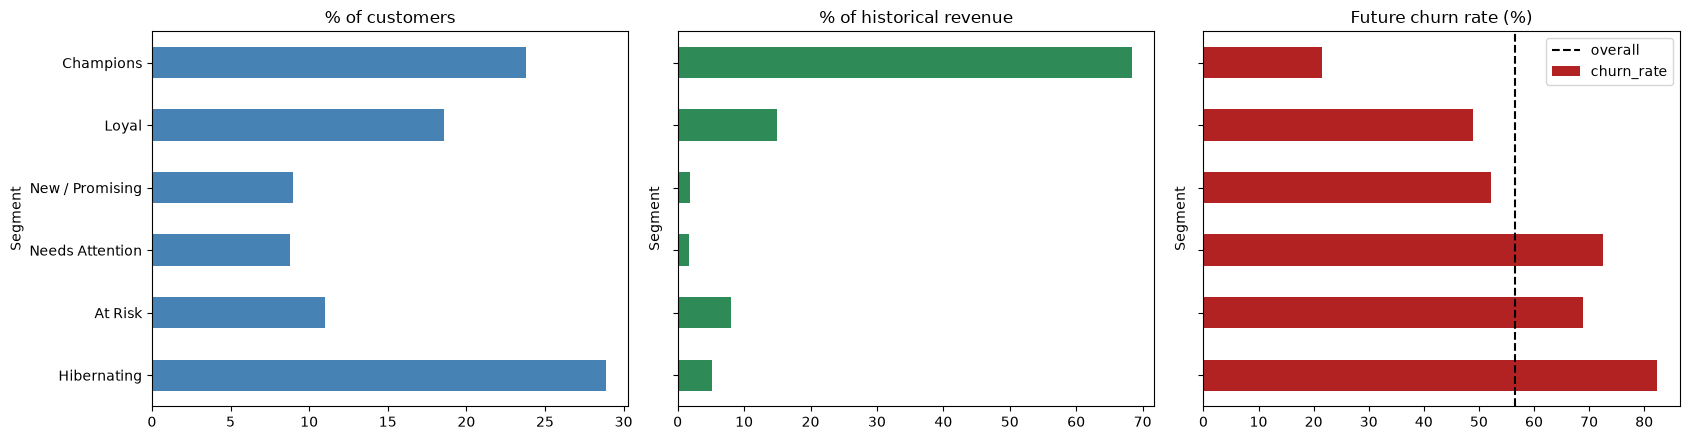

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

seg.loc[order, 'pct_customers'].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('% of customers'); axes[0].invert_yaxis()

seg.loc[order, 'pct_revenue'].plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('% of historical revenue'); axes[1].invert_yaxis(); axes[1].set_yticklabels([])

seg.loc[order, 'churn_rate'].plot(kind='barh', ax=axes[2], color='firebrick')
axes[2].axvline(scored_train['Churned'].mean() * 100, color='black', linestyle='--', label='overall')
axes[2].set_title('Future churn rate (%)'); axes[2].invert_yaxis(); axes[2].set_yticklabels([])
axes[2].legend()

plt.tight_layout()
plt.savefig('../../reports/rfm_segments.png', dpi=150)
plt.show()

7. R × F heatmap (churn kahan zyada hai?):

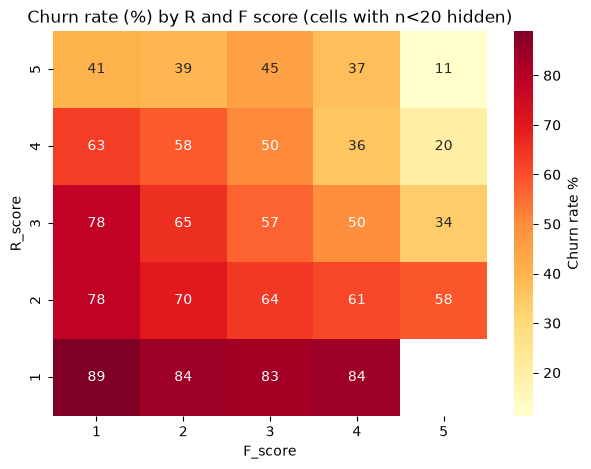

In [10]:
pivot = scored_train.pivot_table(index='R_score', columns='F_score', values='Churned', aggfunc='mean') * 100
counts = scored_train.pivot_table(index='R_score', columns='F_score', values='Churned', aggfunc='count')
pivot = pivot.where(counts >= 20)          # 20 se kam customers wale cells chhupa do (noisy hote hain)

plt.figure(figsize=(7, 5))
sns.heatmap(pivot.sort_index(ascending=False), annot=True, fmt='.0f', cmap='YlOrRd',
            cbar_kws={'label': 'Churn rate %'})
plt.title('Churn rate (%) by R and F score (cells with n<20 hidden)')
plt.show()

8. Pareto check (80/20 rule sach hai kya?):

In [11]:
m = scored_train['Monetary'].sort_values(ascending=False).values
share = m.cumsum() / m.sum()
for pct in [0.01, 0.05, 0.10, 0.20, 0.50]:
    k = int(len(m) * pct)
    print(f"Top {int(pct*100):>2}% customers -> {share[k-1]*100:5.1f}% of historical revenue")

Top  1% customers ->  28.0% of historical revenue
Top  5% customers ->  48.6% of historical revenue
Top 10% customers ->  61.3% of historical revenue
Top 20% customers ->  75.6% of historical revenue
Top 50% customers ->  93.0% of historical revenue


Yeh Day 41 wale “whale customers” ka business version hai.

9. Sabse zaroori sawaal: RFM mein kitna naya signal hai?

In [12]:
print(f"AUC of -Recency alone      : {roc_auc_score(scored_train['Churned'], -scored_train['Recency']):.3f}")
print(f"AUC of RFM_score (low=risk): {roc_auc_score(scored_train['Churned'], -scored_train['RFM_score']):.3f}")
print(f"AUC of R_score alone       : {roc_auc_score(scored_train['Churned'], -scored_train['R_score']):.3f}")
print(f"AUC of F_score alone       : {roc_auc_score(scored_train['Churned'], -scored_train['F_score']):.3f}")
print(f"AUC of M_score alone       : {roc_auc_score(scored_train['Churned'], -scored_train['M_score']):.3f}")

AUC of -Recency alone      : 0.239
AUC of RFM_score (low=risk): 0.778
AUC of R_score alone       : 0.748
AUC of F_score alone       : 0.736
AUC of M_score alone       : 0.729


In scores mein koi model fit nahi hua, to train par AUC nikalna jhootha nahi hai. Yeh dikhata hai ki “ek simple RFM rule” kitna door tak jaata hai. Day 74 ke LogReg CV AUC se compare karo:

- Agar RFM_score ka AUC LogReg ke paas hai, to model ne RFM se zyada kuch seekha nahi hai, aur extra features ka fayda kam hai.
- Agar LogReg kaafi upar hai, to Tenure, AvgOrderValue aur UniqueProducts jaisi cheezein kuch naya jod rahi hain.

10. Test set par ek baar confirmation (kuch badalna nahi):

In [13]:
scored_test = scored.loc[idx_te]
check = pd.DataFrame({
    'train churn %': scored_train.groupby('Segment')['Churned'].mean() * 100,
    'test churn %': scored_test.groupby('Segment')['Churned'].mean() * 100,
    'test customers': scored_test.groupby('Segment')['Churned'].count(),
}).loc[order].round(1)
print(check)

                 train churn %  test churn %  test customers
Segment                                                     
Champions                 21.5          19.3             264
Loyal                     49.0          41.6             166
New / Promising           52.1          54.3              92
Needs Attention           72.6          83.0              94
At Risk                   68.8          67.7             124
Hibernating               82.4          83.9             317


Segment ka ordering test par bhi wahi dikhna chahiye (Champions kam, Hibernating zyada). Chhote segments mein test churn rate ke numbers hilenge (kam customers hain), isliye order dekho, exact numbers nahi.

11. Business actions (README ke liye):

In [14]:
actions = pd.DataFrame({
    'Segment': order,
    'Action': ['Reward and early access, upsell',
               'Loyalty points, cross-sell',
               'Nurture: second-purchase incentive (sabse zyada impact wala group)',
               'Soft nudge, light reminder',
               'Win-back offer, personal outreach (high value ho to)',
               'Low-cost email only, ya chhod do'],
})
print(actions.to_string(index=False))

        Segment                                                             Action
      Champions                                    Reward and early access, upsell
          Loyal                                         Loyalty points, cross-sell
New / Promising Nurture: second-purchase incentive (sabse zyada impact wala group)
Needs Attention                                         Soft nudge, light reminder
        At Risk               Win-back offer, personal outreach (high value ho to)
    Hibernating                                   Low-cost email only, ya chhod do


Win-back offer sirf unhi par lagao jinka avg_monetary bada hai, nahi to kharcha baikaar jayega.

12. Reusable code src/features/rfm.py mein daalo (Day 80 ki aadat):

In [15]:
"""RFM scoring and segmentation. Bin edges are fitted on training data only."""
import numpy as np
import pandas as pd

N_BINS = 5


def fit_rfm_bins(df: pd.DataFrame, n: int = N_BINS) -> dict:
    qs = np.linspace(0, 1, n + 1)[1:-1]
    return {c: np.quantile(df[c], qs) for c in ['Recency', 'Frequency', 'Monetary']}


def add_rfm_scores(df: pd.DataFrame, edges: dict, n: int = N_BINS) -> pd.DataFrame:
    out = df.copy()
    out['R_score'] = n - np.searchsorted(edges['Recency'], out['Recency'], side='left')
    out['F_score'] = 1 + np.searchsorted(edges['Frequency'], out['Frequency'], side='left')
    out['M_score'] = 1 + np.searchsorted(edges['Monetary'], out['Monetary'], side='left')
    out['RFM_score'] = out['R_score'] + out['F_score'] + out['M_score']
    return out


def assign_segment(r, f):
    return np.select(
        [(r >= 4) & (f >= 4), (r >= 3) & (f >= 3), (r >= 4) & (f <= 2),
         (r <= 2) & (f >= 3), (r <= 2) & (f <= 2)],
        ['Champions', 'Loyal', 'New / Promising', 'At Risk', 'Hibernating'],
        default='Needs Attention',
    )

13. Output save karo (Day 83-85 ke models ke liye):

In [17]:
scored[['Customer ID', 'R_score', 'F_score', 'M_score', 'RFM_score', 'Segment']].to_csv(
    '../../data/processed/customer_rfm.csv', index=False)

Row order wahi hai jo customer_ml_dataset.csv mein tha, to baad mein index ya Customer ID se merge kar sakte ho.

14. Zaroori cautions (README ke “Limitations” mein bhi likho):

In [18]:
print("""
1. RFM sirf 'kya ho chuka' batata hai; future spend ka andaza nahi deta (CLV Day 82 mein).
2. Segment names aur boundaries ek convention hain. Dusri boundaries doge to churn rates badlenge.
3. Quintile scores relative hote hain: 'Champion' ka matlab apne customer base mein top, kisi absolute standard par nahi.
4. R, F aur M aapas mein correlated hote hain (Day 47). LogReg mein inhe raw features ke saath dalne se
   multicollinearity badh sakti hai; trees (Day 83) ko is se fark nahi padta.
5. Guest customers (22.8% rows ka Customer ID missing) is analysis mein shamil hi nahi hain.
""")


1. RFM sirf 'kya ho chuka' batata hai; future spend ka andaza nahi deta (CLV Day 82 mein).
2. Segment names aur boundaries ek convention hain. Dusri boundaries doge to churn rates badlenge.
3. Quintile scores relative hote hain: 'Champion' ka matlab apne customer base mein top, kisi absolute standard par nahi.
4. R, F aur M aapas mein correlated hote hain (Day 47). LogReg mein inhe raw features ke saath dalne se
   multicollinearity badh sakti hai; trees (Day 83) ko is se fark nahi padta.
5. Guest customers (22.8% rows ka Customer ID missing) is analysis mein shamil hi nahi hain.



practice questions:

1. Segment ki boundaries badlo (jaise “Champions” ke liye R>=5 & F>=5) aur dekho churn rates kaise badalte hain. Kya “best” boundary bhi test se chunna sahi hoga? (Jawab: nahi, train/CV se.)

- Boundaries badalne par kya hota hai: Agar aap rules ko zyada strict kar dete hain (jaise R>=5 & F>=5), toh "Champions" segment bahut chhota ho jayega aur baaki segments ki composition badal jayegi, jisse har segment ke churn rates aur revenue shares bhi change ho jayenge.

- Kya test set se "best" boundary chunna sahi hai? Nahi, bilkul nahi. Test set ko kabhi bhi tuning ya decision-making ke liye use nahi karna chahiye. Agar aap test set par boundaries ya thresholds optimize karoge, toh yeh ek tarah ka data leakage / overfitting ban jayega, kyunki aapne model ya segment rules ko test data ke hisaab se "cheat" karke fit kar liya hai. Hamesha boundaries train data ya Cross-Validation (CV) ke base par hi set karni chahiye taaki unseen data par bhi rules reliable rahen.

2. seg table se apne shabdon mein ek 3-line business recommendation likho: kaunse 2 segments par pehle paisa lagaoge aur kyun? Numbers (pct_revenue, churn_rate) ka reference do.

1. Champions / Loyal Customers (High Revenue Share, Low Churn): Sabse pehla paisa aur focus in par hona chahiye, kyunki ye total revenue ka ek bada hissa (pct_revenue) generate karte hain aur inka future churn rate sabse kam hota hai; inhein early access aur loyalty rewards de kar retain rakha jaye.

2. At Risk / New Promising Segment (High Churn Potential): Dusra focus in high-risk ya promising customers par hona chahiye jahan churn rate upar hota hai; yahan targeted incentives (jaise "second-purchase" discount ya win-back offer) laga kar revenue drain hone se bachaya ja sakta hai.